# Água em Casa: recomendação do uso da água com Programação Dinâmica

Global Solution 2026.2 - CitizenTech - Dynamic Programming
Bruno Santos Castilho - RM 566799

## 1. Cenário e problema

Durante a redução de pressão da Sabesp (22h às 6h), a casa depende só da água da caixa. Quando o Água em Casa avisa que a água não vai durar até as 6h, a família precisa decidir o que ainda dá para fazer naquela noite: banho, louça, máquina de lavar e assim por diante.

O problema: com **L litros disponíveis**, escolher para cada atividade **uma forma de fazer** (por exemplo, banho rápido ou banho normal) ou **deixar para amanhã**, de modo que a soma da prioridade das atividades feitas seja a maior possível sem passar dos litros disponíveis. Em caso de empate, vale a combinação que gasta menos água.

Isso é uma variação do **problema da mochila** (mochila com grupos: de cada grupo se escolhe no máximo uma opção), resolvida aqui com Programação Dinâmica.

Antes de calcular, uma parte da água fica **reservada** para as descargas da madrugada (uma por morador, cerca de 12 L cada).

## 2. Dados e fontes

O arquivo `atividades_agua.csv` tem as atividades, as opções, os litros de cada uma e a prioridade.

| Consumo | Litros | Fonte |
|---|---|---|
| Banho de 15 min (ducha) | 135 | Sabesp, citado por Serasa e SíndicoNet |
| Banho de 5 min, fechando o registro ao ensaboar | 45 | Sabesp, citado por SíndicoNet |
| Louça com torneira meio aberta (15 min) | 117 | Sabesp, citado por SíndicoNet |
| Louça de molho | 20 | Sabesp, citado pela Gazeta SP |
| Máquina de lavar roupa (5 kg) | 135 | Material "Uso racional da água", Escola de Contas do TCM-SP |
| Lavar calçada com mangueira (5 min) | 90 | Material "Uso racional da água", Escola de Contas do TCM-SP |
| Descarga (6 segundos) | 10 a 14 | Sabesp, citado por SíndicoNet |

Links: serasa.com.br/blog/como-economizar-agua-confira-10-dicas-praticas · sindiconet.com.br/informese/16-dicas-para-economizar-agua-em-casa-para-moradores-vida-em-condominio · gazetasp.com.br (Dia Mundial da Água: dicas de como economizar água) · escoladecontas.tcm.sp.gov.br/images/eventos/material/usoagua.pdf

No exemplo, a casa tem 5 moradores e 2 já tomaram banho antes das 22h, por isso o arquivo tem 3 banhos.

As **prioridades** (1 a 10) não vêm de fonte externa: são o padrão do aplicativo, e a família pode mudar. Água para beber vale mais que lavar a calçada, e banho rápido e banho normal têm a mesma prioridade (o objetivo é tomar banho; o desempate escolhe o que gasta menos).

In [1]:
import csv, time, random, itertools
import matplotlib.pyplot as plt

def carregar_atividades(caminho="atividades_agua.csv"):
    # agrupa as opções por atividade: {grupo: (nome, [(opcao, litros, prioridade), ...])}
    grupos = {}
    with open(caminho, encoding="utf-8") as f:
        for linha in csv.DictReader(f):
            nome, opcoes = grupos.setdefault(linha["grupo"], (linha["atividade"], []))
            opcoes.append((linha["opcao"], int(linha["litros"]), int(linha["prioridade"])))
    return list(grupos.values())

ATIVIDADES = carregar_atividades()
for nome, opcoes in ATIVIDADES:
    print(nome)
    for opcao, litros, prio in opcoes:
        print(f"   {opcao:<50} {litros:>4} L   prioridade {prio}")

Encher galão para beber e cozinhar amanhã
   encher 10 L                                          10 L   prioridade 9
Banho do morador 1
   banho rápido (5 min; registro fechado ao ensaboar)   45 L   prioridade 6
   banho normal (15 min)                               135 L   prioridade 6
Banho do morador 2
   banho rápido (5 min; registro fechado ao ensaboar)   45 L   prioridade 6
   banho normal (15 min)                               135 L   prioridade 6
Banho do morador 3
   banho rápido (5 min; registro fechado ao ensaboar)   45 L   prioridade 6
   banho normal (15 min)                               135 L   prioridade 6
Lavar a louça do jantar
   de molho e enxágue rápido                            20 L   prioridade 3
   torneira meio aberta (15 min)                       117 L   prioridade 3
Máquina de lavar roupa
   ciclo de 5 kg                                       135 L   prioridade 2
Lavar a calçada
   mangueira (5 min)                                    90 L   prioridade 1


## 3. Modelagem

- Cada **atividade** é um grupo com uma ou mais **opções** `(opcao, litros, prioridade)`, guardado numa lista de tuplas. A ordem não importa e o acesso é por índice, então a lista é suficiente.
- A **tabela da programação dinâmica** é uma matriz `dp` com `G + 1` linhas (grupos) e `L + 1` colunas (litros de 0 até L). Cada célula `dp[i][w]` guarda o melhor resultado usando só os `i` primeiros grupos com no máximo `w` litros, como a tupla `(prioridade_total, -litros_usados)`. Comparar tuplas no Python já faz o desempate: primeiro maior prioridade, depois menos litros.
- Uma segunda matriz, `escolha[i][w]`, guarda qual opção foi usada, para depois reconstruir o plano.

Por que programação dinâmica? Testar todas as combinações cresce de forma exponencial: com as 7 atividades do exemplo já são 2 x 3 x 3 x 3 x 3 x 2 x 2 = 648 combinações (cada atividade: uma das opções ou nenhuma), e com 20 atividades de 2 opções passam de 3 bilhões. Um algoritmo guloso (pegar primeiro o que tem mais prioridade por litro) é rápido, mas pode errar (seção 6). A PD aproveita que a melhor resposta para `i` atividades e `w` litros depende só das respostas para `i - 1` atividades, que já estão na tabela.

## 4. Algoritmo

In [2]:
def recomendar(atividades, litros_disponiveis):
    G, L = len(atividades), int(litros_disponiveis)
    dp = [[(0, 0)] * (L + 1) for _ in range(G + 1)]     # (prioridade total, -litros usados)
    escolha = [[None] * (L + 1) for _ in range(G + 1)]   # opção usada em cada célula (None = adiar)

    for i in range(1, G + 1):
        nome, opcoes = atividades[i - 1]
        for w in range(L + 1):
            # IDEIA CENTRAL: para a atividade i com w litros, ou ela fica para amanhã
            # (resultado igual ao de i-1 atividades com os mesmos w litros), ou uso
            # uma das opções dela e somo com o melhor de i-1 atividades com o que sobrou.
            melhor, opcao_usada = dp[i - 1][w], None
            for k, (opcao, litros, prioridade) in enumerate(opcoes):
                if litros <= w:
                    prio_antes, neg_litros_antes = dp[i - 1][w - litros]
                    candidato = (prio_antes + prioridade, neg_litros_antes - litros)
                    if candidato > melhor:
                        melhor, opcao_usada = candidato, k
            dp[i][w] = melhor
            escolha[i][w] = opcao_usada

    # Reconstrução: volta da última atividade até a primeira seguindo as escolhas
    plano, w = [], L
    for i in range(G, 0, -1):
        nome, opcoes = atividades[i - 1]
        k = escolha[i][w]
        if k is None:
            plano.append((nome, "deixar para amanhã", 0, 0))
        else:
            opcao, litros, prioridade = opcoes[k]
            plano.append((nome, opcao, litros, prioridade))
            w -= litros
    prioridade_total, neg_litros = dp[G][L]
    return prioridade_total, -neg_litros, plano[::-1]

In [3]:
LITROS_DESCARGA = 12   # Sabesp: 10 a 14 L por descarga

def plano_da_noite(litros_na_caixa, moradores, atividades=ATIVIDADES, mostrar=True):
    reserva = moradores * LITROS_DESCARGA            # uma descarga por morador na madrugada
    disponivel = max(0, litros_na_caixa - reserva)
    prioridade, usados, plano = recomendar(atividades, disponivel)
    if mostrar:
        print(f"Água na caixa: {litros_na_caixa} L | reserva para descargas: {reserva} L | "
              f"disponível: {disponivel} L")
        for nome, opcao, litros, prio in plano:
            print(f"  {nome:<45} {opcao:<50} {litros:>4} L")
        print(f"  Total: {usados} L de {disponivel} L, prioridade {prioridade}\n")
    return prioridade, usados, plano

## 5. Exemplos de entrada e saída

Os litros na caixa vêm da mesma noite simulada da casa C08 usada nas outras partes do projeto (caixa de 1000 L e 5 moradores).

In [4]:
print("Cenário A - 23:00, aviso amarelo, casa C08 com 405 L")
plano_da_noite(405, moradores=5);
print("Cenário B - caixa de 500 L com 230 L, 4 moradores")
plano_da_noite(230, moradores=4);
print("Cenário C - alerta vermelho, 100 L, 5 moradores")
plano_da_noite(100, moradores=5);

Cenário A - 23:00, aviso amarelo, casa C08 com 405 L
Água na caixa: 405 L | reserva para descargas: 60 L | disponível: 345 L
  Encher galão para beber e cozinhar amanhã     encher 10 L                                          10 L
  Banho do morador 1                            banho rápido (5 min; registro fechado ao ensaboar)   45 L
  Banho do morador 2                            banho rápido (5 min; registro fechado ao ensaboar)   45 L
  Banho do morador 3                            banho rápido (5 min; registro fechado ao ensaboar)   45 L
  Lavar a louça do jantar                       de molho e enxágue rápido                            20 L
  Máquina de lavar roupa                        ciclo de 5 kg                                       135 L
  Lavar a calçada                               deixar para amanhã                                    0 L
  Total: 300 L de 345 L, prioridade 32

Cenário B - caixa de 500 L com 230 L, 4 moradores
Água na caixa: 230 L | reserva para descarg

Leitura dos resultados:
- **A:** sobra água para todos os banhos (rápidos, porque gastam menos com a mesma prioridade), a louça de molho, o galão e a máquina de lavar. Só a calçada fica para amanhã.
- **B:** com menos água, a máquina e a calçada ficam para amanhã.
- **C:** com 40 L disponíveis, o sistema recomenda só o essencial: encher o galão e lavar a louça de molho. Os banhos ficam para depois que a pressão voltar.

## 6. Testes

In [5]:
def forca_bruta(atividades, litros_disponiveis):
    # testa todas as combinações (cada atividade: uma das opções ou nenhuma)
    melhor = (0, 0)
    escolhas = [[None] + list(opcoes) for _, opcoes in atividades]
    for combinacao in itertools.product(*escolhas):
        litros = sum(o[1] for o in combinacao if o)
        if litros <= litros_disponiveis:
            prio = sum(o[2] for o in combinacao if o)
            melhor = max(melhor, (prio, -litros))
    return melhor[0], -melhor[1]

def instancia_aleatoria(rng, n_grupos):
    return [(f"atividade {g}", [(f"opção {k}", rng.randint(5, 150), rng.randint(1, 10))
             for k in range(rng.randint(1, 3))]) for g in range(n_grupos)]

rng = random.Random(2026)
erros = 0
for _ in range(300):
    ativ = instancia_aleatoria(rng, rng.randint(1, 7))
    L = rng.randint(0, 400)
    prio, litros, plano = recomendar(ativ, L)
    assert litros <= L                                         # nunca passa da água disponível
    assert sum(p[2] for p in plano) == litros                  # o plano soma os litros informados
    assert sum(p[3] for p in plano) == prio                    # e a prioridade informada
    if (prio, litros) != forca_bruta(ativ, L):
        erros += 1
print("300 casos aleatórios comparados com a força bruta. Diferenças:", erros)

# Casos de borda
assert recomendar(ATIVIDADES, 0)[0] == 0                       # sem água: nada é recomendado
tudo = recomendar(ATIVIDADES, 10_000)
assert tudo[0] == sum(max(o[2] for o in ops) for _, ops in ATIVIDADES)   # água sobrando: tudo é feito
print("Casos de borda: OK")

300 casos aleatórios comparados com a força bruta. Diferenças: 0
Casos de borda: OK


In [6]:
def guloso(atividades, litros_disponiveis):
    # pega primeiro as opções com mais prioridade por litro
    opcoes = sorted(((p / l, g, l, p) for g, (_, ops) in enumerate(atividades) for _, l, p in ops),
                    reverse=True)
    usados, prio, feitos = 0, 0, set()
    for _, g, l, p in opcoes:
        if g not in feitos and usados + l <= litros_disponiveis:
            usados, prio = usados + l, prio + p
            feitos.add(g)
    return prio, usados

contra = [("Lavar a louça", [("normal", 60, 7)]),
          ("Banho A", [("rápido", 50, 5)]),
          ("Banho B", [("rápido", 50, 5)])]
print("Exemplo com 100 L disponíveis:")
print("  guloso:              prioridade", guloso(contra, 100)[0], "(pega a louça e não cabe mais nada)")
print("  programação dinâmica: prioridade", recomendar(contra, 100)[0], "(os dois banhos)")

Exemplo com 100 L disponíveis:
  guloso:              prioridade 7 (pega a louça e não cabe mais nada)
  programação dinâmica: prioridade 10 (os dois banhos)


## 7. Eficiência

- **Tempo:** para cada atividade (G) e cada valor de litros de 0 a L, testa as opções da atividade (no máximo k). Fica **O(G x L x k)**. Como cada atividade tem no máximo 3 opções, na prática é O(G x L).
- **Memória:** as duas tabelas têm (G + 1) x (L + 1) células: **O(G x L)**. Com 7 atividades e 1000 L são 8 mil células.
- **Força bruta:** O((k+1)^G), exponencial no número de atividades.

O L é pequeno (uma caixa tem no máximo alguns milhares de litros), então a PD responde na hora mesmo com muitas atividades. No gráfico, com poucas atividades a força bruta ainda é mais rápida, porque a PD sempre preenche a tabela inteira; a partir de umas 7 atividades a força bruta passa a crescer muito mais rápido.

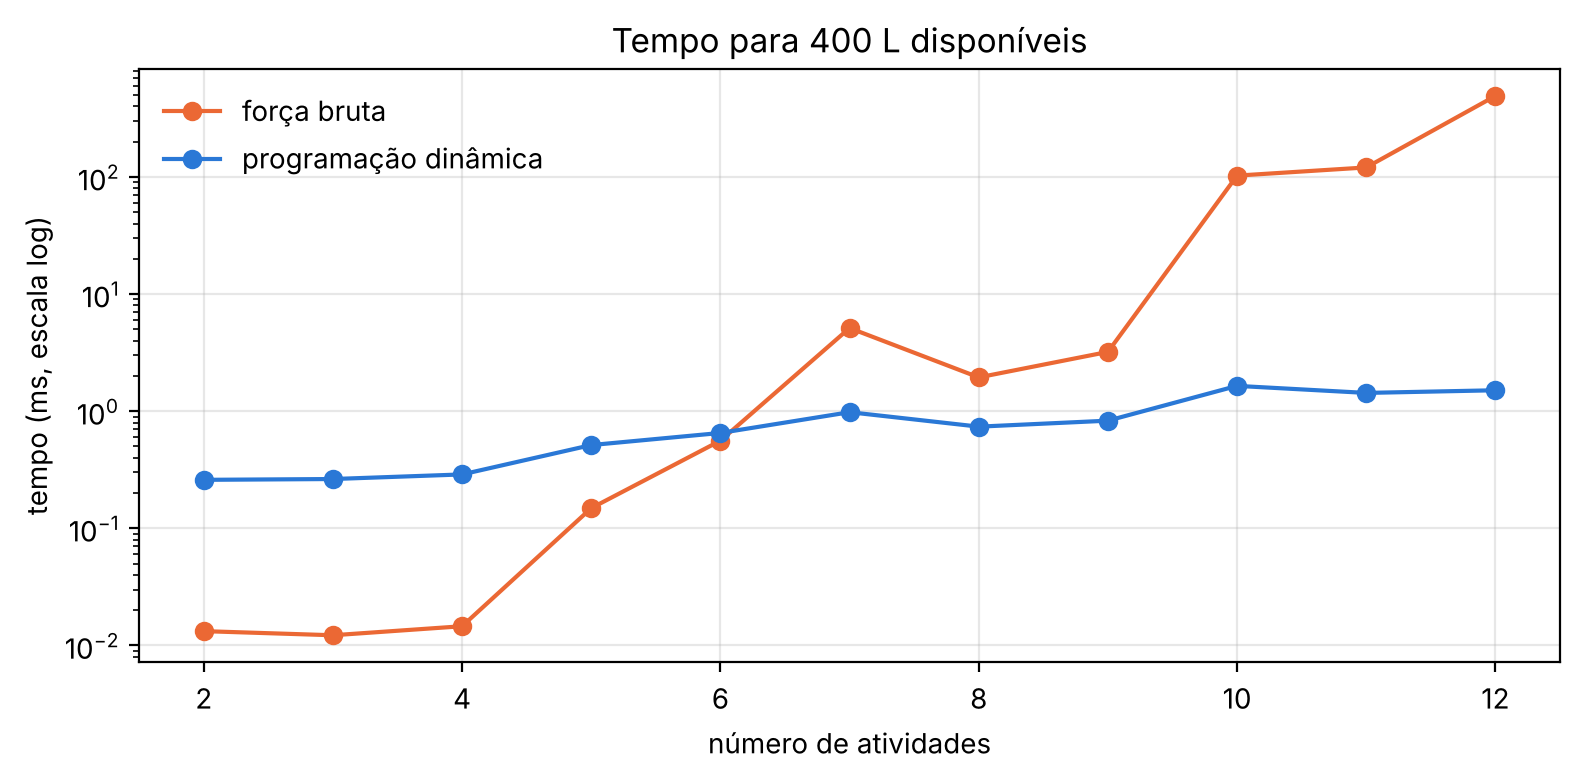

 2 atividades: PD    0.26 ms | força bruta      0.01 ms
 3 atividades: PD    0.26 ms | força bruta      0.01 ms
 4 atividades: PD    0.29 ms | força bruta      0.01 ms
 5 atividades: PD    0.51 ms | força bruta      0.15 ms
 6 atividades: PD    0.65 ms | força bruta      0.56 ms
 7 atividades: PD    0.98 ms | força bruta      5.13 ms
 8 atividades: PD    0.74 ms | força bruta      1.94 ms
 9 atividades: PD    0.83 ms | força bruta      3.21 ms
10 atividades: PD    1.64 ms | força bruta    102.58 ms
11 atividades: PD    1.43 ms | força bruta    120.49 ms
12 atividades: PD    1.51 ms | força bruta    491.38 ms


In [7]:
rng = random.Random(7)
tamanhos = list(range(2, 13))
t_pd, t_fb = [], []
for n in tamanhos:
    ativ = instancia_aleatoria(rng, n)
    t0 = time.perf_counter(); recomendar(ativ, 400); t_pd.append((time.perf_counter() - t0) * 1000)
    t0 = time.perf_counter(); forca_bruta(ativ, 400); t_fb.append((time.perf_counter() - t0) * 1000)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tamanhos, t_fb, marker="o", color="#eb6834", label="força bruta")
ax.plot(tamanhos, t_pd, marker="o", color="#2a78d6", label="programação dinâmica")
ax.set_yscale("log")
ax.set_xlabel("número de atividades")
ax.set_ylabel("tempo (ms, escala log)")
ax.set_title("Tempo para 400 L disponíveis")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
for n, a, b in zip(tamanhos, t_pd, t_fb):
    print(f"{n:>2} atividades: PD {a:7.2f} ms | força bruta {b:9.2f} ms")

## 8. Conclusão

A programação dinâmica encontra sempre a melhor combinação (300 de 300 casos iguais à força bruta) e responde em milissegundos. Com isso, quando o aviso chega, o Água em Casa pode mostrar à família não só "economize", mas **o que fazer com a água que sobrou**: quais banhos, se a louça entra, e o que fica para amanhã.